# Practical 3 — Multiple Linear Regression

**Aim:** Predict a continuous target from **several** features: ŷ = β₀ + β₁x₁ + β₂x₂ + … + β_p x_p, and evaluate with
train/test split, k-fold cross-validation, **MSE** and **R²**.

**Dataset:** Diabetes dataset (442 patients, 10 baseline features: age, sex, bmi, bp and six blood-serum measurements s1–s6).

**Idea:** In matrix form ŷ = Xβ. OLS minimises ‖y − Xβ‖² and has the closed-form **normal equation**
β = (XᵀX)⁻¹ Xᵀ y (X gets an extra column of ones for the intercept).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

pd.set_option("display.precision", 4)

## Evaluation helpers (shared by all regression practicals)
* **MSE** = mean((y - ŷ)²) – average squared error (lower is better)
* **R²** = 1 - SS_res / SS_tot – fraction of the variance of *y* explained by the model (1 is perfect, 0 = no better than predicting the mean)
* `kfold_regression` – manual **k-fold cross-validation**; each fold is held out once as the test set.

In [2]:
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold


def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return pd.Series({"MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)})


def kfold_regression(model, X, y, k=5, seed=42, verbose=True):
    """K-fold CV. Returns (per-fold table, mean/std summary)."""
    X, y = np.asarray(X), np.asarray(y)
    kf = KFold(n_splits=k, shuffle=True, random_state=seed)
    rows = []
    for fold, (tr, te) in enumerate(kf.split(X), start=1):
        m = clone(model).fit(X[tr], y[tr])                 # fresh, untrained copy each fold
        r = regression_metrics(y[te], m.predict(X[te]))
        r.name = f"Fold {fold}"
        rows.append(r)
        if verbose:
            print(f"Fold {fold}: train={len(tr)}, test={len(te)}, MSE={r['MSE']:.2f}, R2={r['R2']:.4f}")
    folds = pd.DataFrame(rows)
    return folds, pd.DataFrame({"mean": folds.mean(), "std": folds.std()})

## Step 1 — Load and explore the data

In [3]:
data = load_diabetes(as_frame=True)
df = data.frame
X_df, y_s = df.drop(columns="target"), df["target"]
print("Shape:", df.shape, "| missing values:", int(df.isna().sum().sum()))
display(df.head())
display(df.describe().T)

Shape: (442, 11) | missing values: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.0381,0.0507,0.0617,0.0219,-0.0442,-0.0348,-0.0434,-0.0026,0.0199,-0.0176,151.0
1,-0.0019,-0.0446,-0.0515,-0.0263,-0.0084,-0.0192,0.0744,-0.0395,-0.0683,-0.0922,75.0
2,0.0853,0.0507,0.0445,-0.0057,-0.0456,-0.0342,-0.0324,-0.0026,0.0029,-0.0259,141.0
3,-0.0891,-0.0446,-0.0116,-0.0367,0.0122,0.0250,-0.0360,0.0343,0.0227,-0.0094,206.0
4,0.0054,-0.0446,-0.0364,0.0219,0.0039,0.0156,0.0081,-0.0026,-0.0320,-0.0466,135.0


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.5118e-19,0.0476,-0.1072,-0.0373,0.0054,0.0381,0.1107
sex,442.0,1.2308e-17,0.0476,-0.0446,-0.0446,-0.0446,0.0507,0.0507
bmi,442.0,-2.2456e-16,0.0476,-0.0903,-0.0342,-0.0073,0.0312,0.1706
bp,442.0,-4.7976e-17,0.0476,-0.1124,-0.0367,-0.0057,0.0356,0.1320
s1,442.0,-1.3815e-17,0.0476,-0.1268,-0.0342,-0.0043,0.0284,0.1539
s2,442.0,3.9184e-17,0.0476,-0.1156,-0.0304,-0.0038,0.0298,0.1988
s3,442.0,-5.7772e-18,0.0476,-0.1023,-0.0351,-0.0066,0.0293,0.1812
s4,442.0,-9.0425e-18,0.0476,-0.0764,-0.0395,-0.0026,0.0343,0.1852
s5,442.0,9.2686e-17,0.0476,-0.1261,-0.0332,-0.0019,0.0324,0.1336
s6,442.0,1.1303e-17,0.0476,-0.1378,-0.0332,-0.0011,0.0279,0.1356


### Correlation matrix
Strong correlation *between features* (e.g. s1–s2, s3–s4) is called **multicollinearity**; it makes individual
coefficients unstable even if overall predictions are fine.

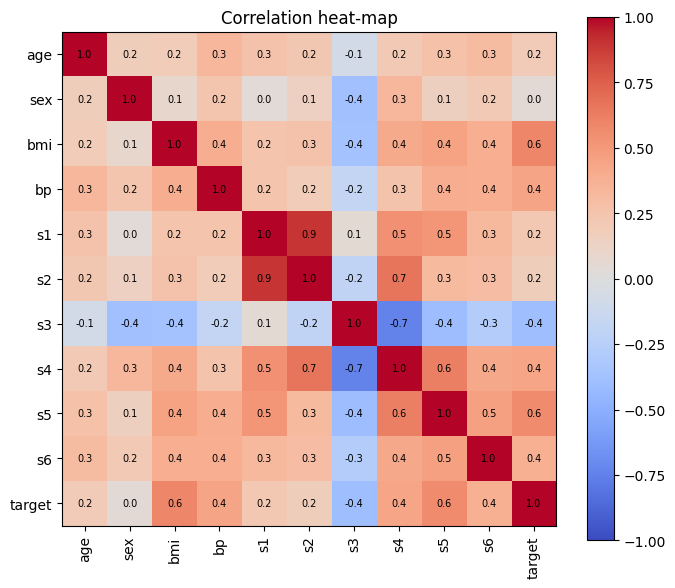

Correlation of each feature with the target:
bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
s3    -0.395


In [4]:
corr = df.corr()
plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=90); plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(); plt.title("Correlation heat-map"); plt.tight_layout(); plt.show()

print("Correlation of each feature with the target:")
print(corr["target"].drop("target").sort_values(ascending=False).round(3).to_string())

## Step 2 — Train / test split

In [5]:
X, y = X_df.values, y_s.values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (353, 10) Test: (89, 10)


## Step 3 — What does `fit()` do? (normal equation by hand)
1. Prepend a column of 1s to X so the intercept β₀ is learned like any other coefficient.
2. Compute XᵀX (a (p+1)×(p+1) matrix) and Xᵀy.
3. Solve (XᵀX)β = Xᵀy for β (`np.linalg.solve` is more stable than explicitly inverting).

In [6]:
Xb = np.column_stack([np.ones(len(X_train)), X_train])
print("Step 3.1  design matrix with bias column:", Xb.shape)
XtX = Xb.T @ Xb
Xty = Xb.T @ y_train
print("Step 3.2  XᵀX shape:", XtX.shape, "| Xᵀy shape:", Xty.shape)
beta = np.linalg.solve(XtX, Xty)
print("Step 3.3  β =", beta.round(3))

Step 3.1  design matrix with bias column: (353, 11)
Step 3.2  XᵀX shape: (11, 11) | Xᵀy shape: (11,)
Step 3.3  β = [ 151.346   37.904 -241.964  542.429  347.704 -931.489  518.062  163.42
  275.318  736.199   48.671]


## Step 4 — Fit scikit-learn's `LinearRegression` and compare

Intercept  sklearn: 151.3456 | manual: 151.3456
Coefficients identical: True


,coefficient
s1,-931.49
sex,-241.96
age,37.90
s6,48.67
s3,163.42
s4,275.32
bp,347.70
s2,518.06
bmi,542.43
s5,736.20


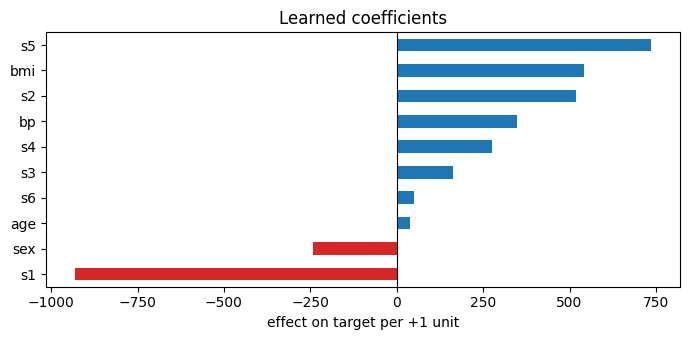

In [7]:
model = LinearRegression().fit(X_train, y_train)
print("Intercept  sklearn: %.4f | manual: %.4f" % (model.intercept_, beta[0]))
print("Coefficients identical:", np.allclose(model.coef_, beta[1:]))

coef = pd.Series(model.coef_, index=X_df.columns).sort_values()
display(coef.to_frame("coefficient").round(2))

plt.figure(figsize=(7, 3.5))
coef.plot.barh(color=np.where(coef > 0, "tab:blue", "tab:red"))
plt.axvline(0, color="k", lw=0.8); plt.title("Learned coefficients"); plt.xlabel("effect on target per +1 unit")
plt.tight_layout(); plt.show()

## Step 5 — Predictions and metrics
`predict` computes ŷ = Xβ + β₀ for every test row. For multiple regression we also report **adjusted R²**,
which penalises useless features: R²_adj = 1 − (1 − R²)(n − 1)/(n − p − 1).

In [8]:
y_pred = model.predict(X_test)
n, p = X_test.shape
train_m = regression_metrics(y_train, model.predict(X_train))
test_m = regression_metrics(y_test, y_pred)
test_m["Adj_R2"] = 1 - (1 - test_m["R2"]) * (n - 1) / (n - p - 1)
train_m["Adj_R2"] = np.nan

print("Manual check of the first prediction:",
      round(float(model.intercept_ + X_test[0] @ model.coef_), 4), "== sklearn:", round(float(y_pred[0]), 4))
display(pd.DataFrame({"Train": train_m, "Test": test_m}))

Manual check of the first prediction: 139.5476 == sklearn: 139.5476


,Train,Test
MSE,2868.5497,2900.1936
RMSE,53.5588,53.8534
R2,0.5279,0.4526
Adj_R2,NaN,0.3824


## Step 6 — Diagnostics

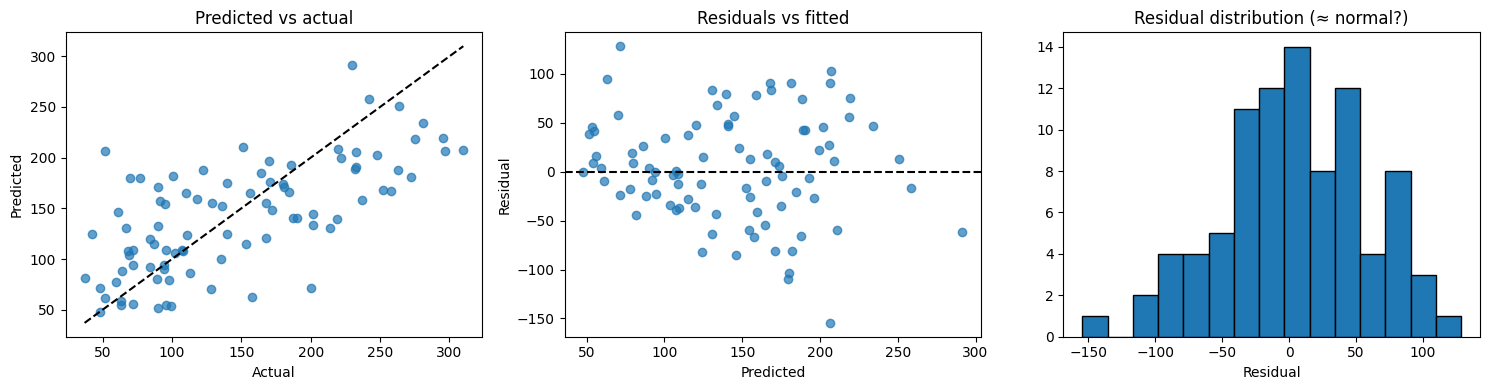

In [9]:
residuals = y_test - y_pred
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(y_test, y_pred, alpha=0.7)
lims = [y_test.min(), y_test.max()]; ax[0].plot(lims, lims, "k--")
ax[0].set(xlabel="Actual", ylabel="Predicted", title="Predicted vs actual")
ax[1].scatter(y_pred, residuals, alpha=0.7); ax[1].axhline(0, color="k", ls="--")
ax[1].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs fitted")
ax[2].hist(residuals, bins=15, edgecolor="k"); ax[2].set(xlabel="Residual", title="Residual distribution (≈ normal?)")
plt.tight_layout(); plt.show()

### Variance Inflation Factor (VIF) – quantifying multicollinearity
For each feature j regress it on all *other* features, get R²_j, then VIF_j = 1/(1 − R²_j).
Rule of thumb: VIF > 5–10 means the feature is largely explained by the others.

In [10]:
vif = {}
for j, name in enumerate(X_df.columns):
    others = np.delete(X_train, j, axis=1)
    r2_j = LinearRegression().fit(others, X_train[:, j]).score(others, X_train[:, j])
    vif[name] = 1 / (1 - r2_j)
display(pd.Series(vif, name="VIF").sort_values(ascending=False).to_frame().round(2))

,VIF
s1,55.25
s2,35.76
s3,14.29
s5,10.07
s4,9.33
bmi,1.57
s6,1.50
bp,1.42
sex,1.27
age,1.22


## Step 7 — k-fold cross-validation (k = 5)

In [11]:
folds, summary = kfold_regression(LinearRegression(), X, y, k=5)
print()
display(folds.round(4))
display(summary.round(4))

Fold 1: train=353, test=89, MSE=2900.19, R2=0.4526
Fold 2: train=353, test=89, MSE=2662.64, R2=0.5732
Fold 3: train=354, test=88, MSE=3312.31, R2=0.3914
Fold 4: train=354, test=88, MSE=2797.88, R2=0.5843
Fold 5: train=354, test=88, MSE=3403.89, R2=0.3908



,MSE,RMSE,R2
Fold 1,2900.1936,53.8534,0.4526
Fold 2,2662.6376,51.6008,0.5732
Fold 3,3312.3059,57.5526,0.3914
Fold 4,2797.8836,52.8950,0.5843
Fold 5,3403.8878,58.3428,0.3908


,mean,std
MSE,3015.3817,325.6160
RMSE,54.8489,2.9528
R2,0.4785,0.0950


## Step 8 — Simple vs multiple regression
Does adding features help? Compare the 5-fold CV score of BMI only against all 10 features.

In [12]:
_, s_simple = kfold_regression(LinearRegression(), X_df[["bmi"]], y, verbose=False)
comparison = pd.DataFrame({"Simple (bmi only)": s_simple["mean"], "Multiple (10 features)": summary["mean"]})
display(comparison.round(4))

,Simple (bmi only),Multiple (10 features)
MSE,3939.1859,3015.3817
RMSE,62.7497,54.8489
R2,0.3207,0.4785


### Conclusion
* Using all features lowers the cross-validated MSE and raises R² noticeably compared with BMI alone.
* Coefficients of correlated features (s1, s2, s3, s4, s5) are large with opposite signs and have high VIF – the model predicts well but individual coefficients should be interpreted with caution. Practical 5 (Ridge/Lasso) addresses this.
* Residuals are roughly symmetric around zero, so the linear model's assumptions are acceptable.